# 03 — Modelagem e Avaliação

Este notebook realiza o treinamento e a avaliação dos modelos de aprendizado de máquina utilizados para classificar a direção do Ibovespa cinco pregões à frente.

Modelos avaliados:
- Baseline Majority
- Baseline Persistence
- Regressão Logística
- Árvore de Decisão
- Random Forest

A divisão dos dados respeita a ordem cronológica da série temporal, evitando vazamento de informações futuras.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.metrics import (
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

import json

In [3]:
# Caminho do dataset processado
arquivo_dataset = Path("../data/processed/ibovespa_features.csv")

# Carregar dados
df = pd.read_csv(
    arquivo_dataset,
    parse_dates=["Date"]
)

print("Dimensões: ", df.shape)

display(df.head())

Dimensões:  (3950, 9)


,Date,Retorno_Diario,Retorno_5d,Retorno_10d,Media_Retorno_5d,Volatilidade_5d,Variacao_Intradiaria,Amplitude_Diaria,Direcao_Futura
0,2010-01-18,0.613239,-1.465222,-0.919409,-0.292293,0.787222,0.605946,1.108969,0
1,2010-01-19,0.731978,-0.238313,-0.471241,-0.044524,0.890929,0.739236,1.697475,0
2,2010-01-20,-2.444607,-3.104355,-3.575620,-0.621636,1.326126,-2.433442,3.486513,0
3,2010-01-21,-2.829912,-5.058667,-5.934621,-1.021674,1.663390,-2.829912,3.730529,0
4,2010-01-22,-0.075449,-3.998376,-5.754095,-0.800950,1.709857,-0.066401,1.856521,1


In [4]:
print("### Validação do dataset ###")

print("\nDimensões:", df.shape)

print("\nPeríodo:")
print("Inicial:", df["Date"].min())
print("Final:", df["Date"].max())

print("\nValores ausentes:")
print(df.isna().sum())

print("\nValores infinitos:")
print(
    np.isinf(
        df.select_dtypes(include="number")
    ).sum()
)

print("\nDistribuição do target:")
print(
    df["Direcao_Futura"]
    .map({0: "QUEDA", 1: "ALTA"})
    .value_counts()
)

### Validação do dataset ###

Dimensões: (3950, 9)

Período:
Inicial: 2010-01-18 00:00:00
Final: 2025-12-19 00:00:00

Valores ausentes:
Date                    0
Retorno_Diario          0
Retorno_5d              0
Retorno_10d             0
Media_Retorno_5d        0
Volatilidade_5d         0
Variacao_Intradiaria    0
Amplitude_Diaria        0
Direcao_Futura          0
dtype: int64

Valores infinitos:
Retorno_Diario          0
Retorno_5d              0
Retorno_10d             0
Media_Retorno_5d        0
Volatilidade_5d         0
Variacao_Intradiaria    0
Amplitude_Diaria        0
Direcao_Futura          0
dtype: int64

Distribuição do target:
Direcao_Futura
ALTA     2082
QUEDA    1868
Name: count, dtype: int64


In [5]:
# Definição das features e target que o modelo usará pra aprender e pra prever

features = [
    "Retorno_Diario",
    "Retorno_5d",
    "Retorno_10d",
    "Media_Retorno_5d",
    "Volatilidade_5d",
    "Variacao_Intradiaria",
    "Amplitude_Diaria",
]

target = "Direcao_Futura"

X = df[features].copy()
y = df[target].copy()

print("Features:")
print(features)

print("\nDimensão de X:", X.shape)
print("\nDimensão de y:", y.shape)

Features:
['Retorno_Diario', 'Retorno_5d', 'Retorno_10d', 'Media_Retorno_5d', 'Volatilidade_5d', 'Variacao_Intradiaria', 'Amplitude_Diaria']

Dimensão de X: (3950, 7)

Dimensão de y: (3950,)


In [6]:
# Separação das bases de treino, validação e teste

# Total de observações
n = len(df)

# Definir os pontos de corte
i_train = int(n * 0.70)
i_val = int(n * 0.85)

# Divisão cronologica
X_train = X.iloc[:i_train]
y_train = y.iloc[:i_train]

X_val = X.iloc[i_train:i_val]
y_val = y.iloc[i_train:i_val]

X_test = X.iloc[i_val:]
y_test = y.iloc[i_val:]

print("### Dimensões ###")
print("Treinamento:", X_train.shape)
print("Validação:", X_val.shape)
print("Teste:", X_test.shape)

### Dimensões ###
Treinamento: (2765, 7)
Validação: (592, 7)
Teste: (593, 7)


In [7]:
# Conferencia das datas de cada conjunto
print("### Períodos ###")

print(
    "\nTreinamento:",
    df["Date"].iloc[0],
    "→",
    df["Date"].iloc[i_train - 1]
)

print(
    "Validação:",
    df["Date"].iloc[i_train],
    "→",
    df["Date"].iloc[i_val - 1]
)

print(
    "Teste:",
    df["Date"].iloc[i_val],
    "→",
    df["Date"].iloc[-1]
)

### Períodos ###

Treinamento: 2010-01-18 00:00:00 → 2021-03-25 00:00:00
Validação: 2021-03-26 00:00:00 → 2023-08-08 00:00:00
Teste: 2023-08-09 00:00:00 → 2025-12-19 00:00:00


In [8]:
def mostrar_distribuicao(nome, y):
    distribuicao = (
        y.map({0: "QUEDA", 1: "ALTA"})
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )

    print(f"\n{nome}:")
    print(distribuicao)


mostrar_distribuicao("Treinamento", y_train)
mostrar_distribuicao("Validação", y_val)
mostrar_distribuicao("Teste", y_test)


Treinamento:
Direcao_Futura
ALTA     53.78
QUEDA    46.22
Name: proportion, dtype: float64

Validação:
Direcao_Futura
QUEDA    51.86
ALTA     48.14
Name: proportion, dtype: float64

Teste:
Direcao_Futura
ALTA     52.28
QUEDA    47.72
Name: proportion, dtype: float64


### Antes dos modelos de ML, precisamos estabelecer algumas referências.

### Primeira Referencia: Majority Baseline

> A regra que vamos usar para ele é: utilizar a direção mais frequente observada no dataset para aplicar à todas as previsões.

O Majority Baseline prevê a classe mais frequente no conjunto de treinamento para todas as observações futuras.

Por exemplo, se:
Treinamento:
```
ALTA   55%
QUEDA  45%
```
o baseline simplesmente diz:
"Vou prever ALTA para todo mundo."

Isso parece extremamente simples — e é justamente essa a ideia.

In [9]:
# Implementação do Majority Baseline

# Identificar a classe majoritária no treinamento
classe_majoritaria = y_train.mode()[0]

print("Classe majoritária:", classe_majoritaria)

# Prever a classe majoritária para validação e teste
y_val_majority = np.full(
    len(y_val),
    classe_majoritaria
)

y_test_majority = np.full(
    len(y_test),
    classe_majoritaria
)

Classe majoritária: 1


In [10]:
# Função de avaliação do modelo
def avaliar_modelo(nome, y_true, y_pred):
    return {
        "model": nome,
        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),
        "precision_high": precision_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),
        "recall_high": recall_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),
        "f1_high": f1_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        )
    }

Para interpretar a matriz de confusão, o segredo é separar as duas ideias:
- True/False → se a previsão estava correta ou errada.
- Positive/Negative → qual classe o modelo previu.

Então:
- TP (true positivo) → previu ALTA e era ALTA
- FP (falso positivo) → previu ALTA e era QUEDA
- FN (falso negativo) → previu QUEDA e era ALTA
- TN (true negativo) → previu QUEDA e era QUEDA

Na leitura da tabela fica:
|  |  |
| --- | --- |
| True negativo | Falso positivo |
| Falso negativo | True positivo |


Avaliação da Majority Baseline:
{
    "model": "Majority",
    "balanced_accuracy": 0.5,
    "precision_high": 0.5227655986509275,
    "recall_high": 1.0,
    "f1_high": 0.6866002214839424
}

Matriz de confusão:
[[  0 283]
 [  0 310]] 



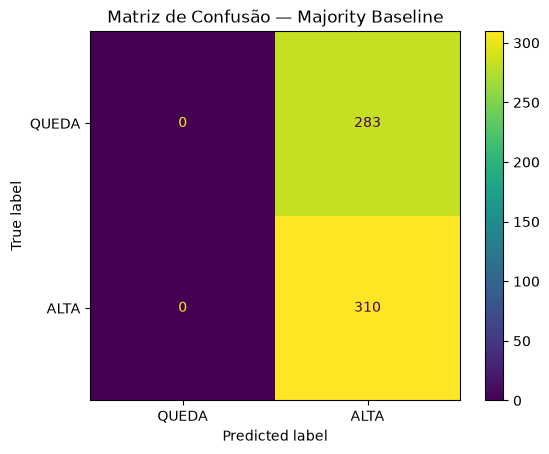

In [11]:
# Avaliação da Majority Baseline
resultado_majority = avaliar_modelo(
    "Majority",
    y_test,
    y_test_majority
)
print("Avaliação da Majority Baseline:")
print(json.dumps(resultado_majority, ensure_ascii=False, indent=4))


# Matriz de confusão do Majority Baseline
cm_majority = confusion_matrix(
    y_test,
    y_test_majority
)

print("\nMatriz de confusão:")
print(cm_majority, "\n")

# Transformando em uma matriz visual
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_majority,
    display_labels=["QUEDA", "ALTA"]
)

disp.plot()

plt.title("Matriz de Confusão — Majority Baseline")
plt.show()

### Segunda Referencia: Persistence Baseline

> A regra que vamos usar para o Persistence Baseline: utilizar a direção observada nos últimos 5 pregões (Retorno_5d) como previsão da direção dos próximos 5 pregões.

O Persistence Baseline tenta ser um pouco mais inteligente que o Majority:
"Vou usar o comportamento mais recente conhecido para fazer minha previsão."

Isso é importante porque queremos responder uma pergunta:
Um modelo de Machine Learning consegue fazer algo melhor do que simplesmente assumir que o comportamento recente continuará?

Avaliação da Persistence Baseline:
{
    "model": "Persistence",
    "balanced_accuracy": 0.5203921121623163,
    "precision_high": 0.5424836601307189,
    "recall_high": 0.535483870967742,
    "f1_high": 0.538961038961039
}

Matriz de confusão:
[[143 140]
 [144 166]] 



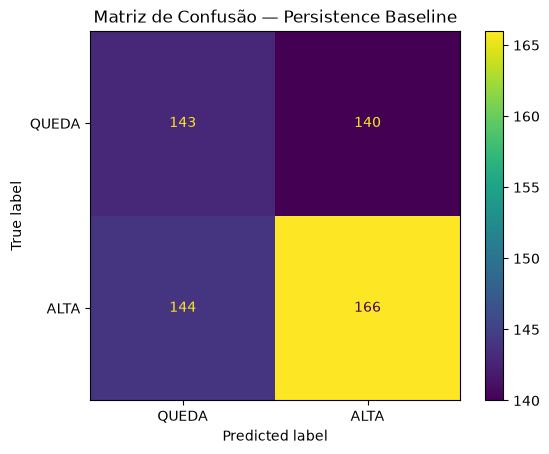

In [12]:
# Aplicação da regra definida para essa baseline
y_test_persistence = (X_test["Retorno_5d"] > 0).astype(int)
y_test_persistence.head(10)

# Avaliação da Persistence Baseline
resultado_persistence = avaliar_modelo(
    "Persistence",
    y_test,
    y_test_persistence
)
print("Avaliação da Persistence Baseline:")
print(json.dumps(resultado_persistence, ensure_ascii=False, indent=4))

# Avaliação da matriz de confusão
cm_persistence = confusion_matrix(
    y_test,
    y_test_persistence
)

print("\nMatriz de confusão:")
print(cm_persistence, "\n")

# Transformando em uma matriz visual
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_persistence,
    display_labels=["QUEDA", "ALTA"]
)

disp.plot()

plt.title("Matriz de Confusão — Persistence Baseline")
plt.show()

Até aqui, nossos dois baselines não "aprenderam" nada:

#### Majority - Regra:
Seja qual for a situação → ALTA

#### Persistence - Regra:
Se Retorno_5d > 0 → ALTA
Se Retorno_5d < 0 → QUEDA


Agora vem a mudança de paradigma:

### Primeiro modelo: Regressão Logística

Ele vai receber as sete features:
```
Retorno_Diario
Retorno_5d
Retorno_10d
Media_Retorno_5d
Volatilidade_5d
Variacao_Intradiaria
Amplitude_Diaria
```
tentar aprender uma relação entre essas variáveis e retornar a `Direcao_Futura`

A grande pergunta passa a ser:
> Será que uma combinação dessas informações permite prever melhor os próximos cinco pregões do que nossas duas regras simples?

Avaliação do Modelo 1: Logistic Regression:
{
    "model": "Logistic Regression",
    "balanced_accuracy": 0.5089137125270717,
    "precision_high": 0.5274336283185841,
    "recall_high": 0.9612903225806452,
    "f1_high": 0.6811428571428572
}

Matriz de confusão:
[[ 16 267]
 [ 12 298]] 



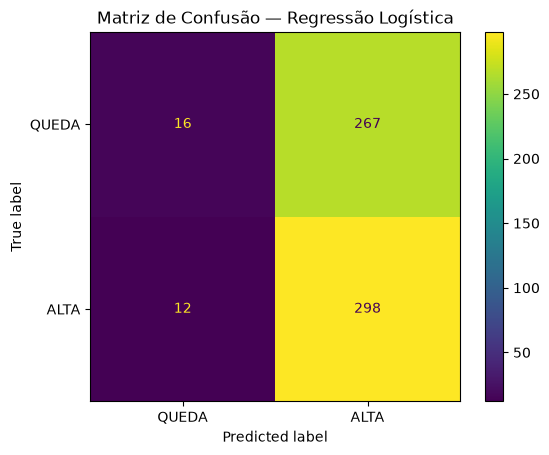

In [13]:
# Criando o scaler, que será usado para converter os valores das features em uma escala comparável
scaler = StandardScaler()

# Cria a escala que será usada em todas as partes do dataset, para evitar vazamento de dados
scaler.fit(X_train)

# Aplica essa escala em cada conjunto de dados
X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Criação do modelo
modelo_logistico = LogisticRegression(
    random_state=42
)

# Onde de fato o modelo começa a aprender
modelo_logistico.fit(
    X_train_scaled,
    y_train
)

# A primeira previsão
y_test_logistic = modelo_logistico.predict(
    X_test_scaled
)

# Retornando apenas as probabilidades, para utilizar em uma outra regra de threshold
y_proba = modelo_logistico.predict_proba(
    X_test_scaled
)

# AVALIACAO DO MODELO
resultado_logistic = avaliar_modelo(
    "Logistic Regression",
    y_test,
    y_test_logistic
)
print("Avaliação do Modelo 1: Logistic Regression:")
print(json.dumps(resultado_logistic, ensure_ascii=False, indent=4))

# Avaliação da matriz de confusão
cm_logistic = confusion_matrix(
    y_test,
    y_test_logistic
)

print("\nMatriz de confusão:")
print(cm_logistic, "\n")

# Transformando em uma matriz visual
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_logistic,
    display_labels=["QUEDA", "ALTA"]
)

disp.plot()
plt.title("Matriz de Confusão — Regressão Logística")
plt.show()

In [14]:
# Depurando o aprendizado do modelo

# Pesos aprendidos pelo modelo
print("Pesos aprendidos pelo modelo:")
pesos_logistic = pd.DataFrame({
    "Feature": X_train.columns,
    "Coeficiente": modelo_logistico.coef_[0]
})
print(pesos_logistic, "\n")

# Intercepto
print("\nIntercepto constante da equação")
print(modelo_logistico.intercept_, "\n")

# Ordenando os pesos para pegar o mais "relevante"
pesos_logistic["Importancia_Absoluta"] = (
    pesos_logistic["Coeficiente"].abs()
)
print("\nPesos com maior magnitude na decisão do modelo")
print(
    pesos_logistic.sort_values(
    "Importancia_Absoluta",
    ascending=False
))

# Visualizando as probabilidades calculadas pelo modelo para cada previsão
probabilidades = modelo_logistico.predict_proba(
    X_test_scaled
)
print("\nProbabilidades do modelo")
print(probabilidades[:10])

Pesos aprendidos pelo modelo:
                Feature  Coeficiente
0        Retorno_Diario    -0.007421
1            Retorno_5d    -0.049401
2           Retorno_10d     0.172398
3      Media_Retorno_5d    -0.046046
4       Volatilidade_5d    -0.005799
5  Variacao_Intradiaria    -0.006800
6      Amplitude_Diaria     0.067735 


Intercepto constante da equação
[0.15217805] 


Pesos com maior magnitude na decisão do modelo
                Feature  Coeficiente  Importancia_Absoluta
2           Retorno_10d     0.172398              0.172398
6      Amplitude_Diaria     0.067735              0.067735
1            Retorno_5d    -0.049401              0.049401
3      Media_Retorno_5d    -0.046046              0.046046
0        Retorno_Diario    -0.007421              0.007421
5  Variacao_Intradiaria    -0.006800              0.006800
4       Volatilidade_5d    -0.005799              0.005799

Probabilidades do modelo
[[0.4901815  0.5098185 ]
 [0.47262576 0.52737424]
 [0.47663115 0.52336885]
 [0

In [17]:
# Experimento com threshold de 55%
threshold = 0.55

y_pred_test = (y_proba[:, 1] >= threshold).astype(int)

print("Matriz de confusão:")
print(confusion_matrix(y_test, y_pred_test))

print("\nAvaliação com threshold de 55%:")

print("Balanced Accuracy:",
      balanced_accuracy_score(y_test, y_pred_test))

print("Precision (ALTA):",
      precision_score(y_test, y_pred_test))

print("Recall (ALTA):",
      recall_score(y_test, y_pred_test))

print("F1 (ALTA):",
      f1_score(y_test, y_pred_test))


Matriz de confusão:
[[249  34]
 [260  50]]

Avaliação com threshold de 55%:
Balanced Accuracy: 0.5205744899122308
Precision (ALTA): 0.5952380952380952
Recall (ALTA): 0.16129032258064516
F1 (ALTA): 0.25380710659898476
